# Project 01: Exam Score Predictor Using Linear Regression

## Problem Statement
Can we predict a student's exam score based on the number of hours they study?

## Objective
Build a Machine Learning model that learns the relationship between study hours and exam scores.

## Concepts Covered
- Features and target variables
- Exploratory Data Analysis
- Linear Regression
- Training and testing datasets
- Model evaluation
- Predictions on new data

## Tools
Python, Pandas, NumPy, Matplotlib, and Scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
data = {
    "Hours_Studied": [
        1, 1.5, 2, 2.5, 3,
        3.5, 4, 4.5, 5, 5.5,
        6, 6.5, 7, 7.5, 8,
        8.5, 9, 9.5, 10
    ],
    "Exam_Score": [
        35, 37, 40, 43, 45,
        48, 52, 54, 58, 60,
        63, 67, 70, 73, 78,
        80, 84, 87, 91
    ]
}

df = pd.DataFrame(data)

display(df.head())

,Hours_Studied,Exam_Score
0,1.0,35
1,1.5,37
2,2.0,40
3,2.5,43
4,3.0,45


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (19, 2)

Column names:
['Hours_Studied', 'Exam_Score']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Hours_Studied  19 non-null     float64
 1   Exam_Score     19 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 436.0 bytes

Statistical summary:


,Hours_Studied,Exam_Score
count,19.000000,19.000000
mean,5.500000,61.315789
std,2.813657,17.638508
min,1.000000,35.000000
25%,3.250000,46.500000
50%,5.500000,60.000000
75%,7.750000,75.500000
max,10.000000,91.000000


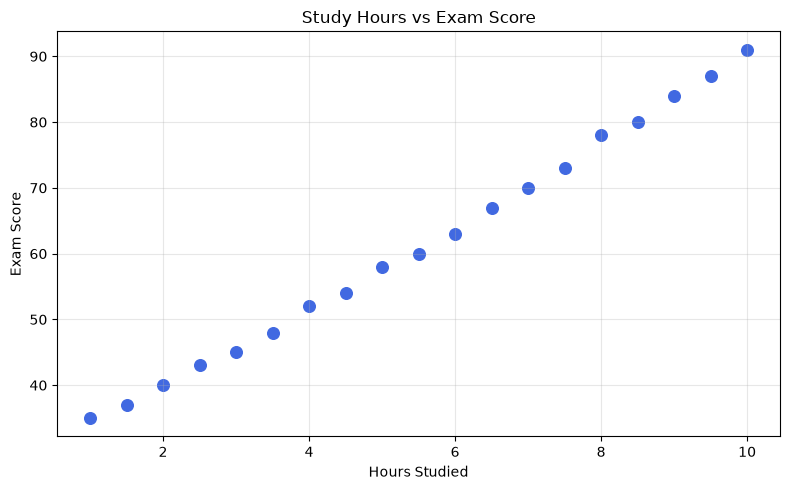

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Hours_Studied"],
    df["Exam_Score"],
    color="royalblue",
    s=70
)

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
correlation = df["Hours_Studied"].corr(df["Exam_Score"])

print(f"Correlation: {correlation:.3f}")

Correlation: 0.999


In [7]:
# Input feature (X)
X = df[["Hours_Studied"]]

# Target variable (y)
y = df["Exam_Score"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining features:")
display(X_train.head())

print("\nTesting features:")
display(X_test.head())

Training samples: 15
Testing samples: 4

Training features:


,Hours_Studied
8,5.0
16,9.0
3,2.5
13,7.5
15,8.5



Testing features:


,Hours_Studied
0,1.0
5,3.5
11,6.5
1,1.5


In [8]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Model training completed!")

print(f"Slope (m): {model.coef_[0]:.2f}")
print(f"Intercept (c): {model.intercept_:.2f}")

Model training completed!
Slope (m): 6.37
Intercept (c): 26.10


In [9]:
# Predict scores for the test data
y_pred = model.predict(X_test)

# Compare actual and predicted scores
results = pd.DataFrame({
    "Hours_Studied": X_test["Hours_Studied"].values,
    "Actual_Score": y_test.values,
    "Predicted_Score": np.round(y_pred, 2)
})

results["Absolute_Error"] = np.abs(
    results["Actual_Score"] - results["Predicted_Score"]
)

display(results.sort_values("Hours_Studied"))

,Hours_Studied,Actual_Score,Predicted_Score,Absolute_Error
0,1.0,35,32.48,2.52
3,1.5,37,35.66,1.34
1,3.5,48,48.41,0.41
2,6.5,67,67.54,0.54


In [10]:
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R² Score: {r2:.3f}")

Mean Absolute Error (MAE): 1.20
R² Score: 0.987


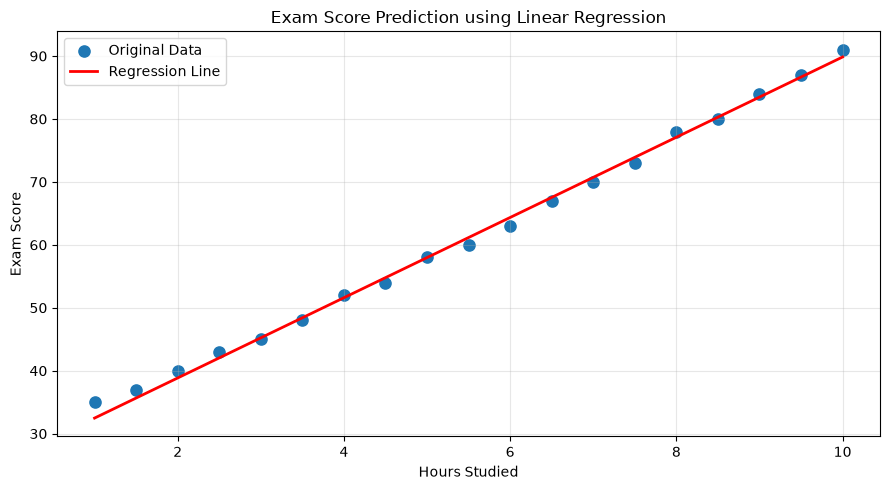

In [11]:
# Generate points for a smooth regression line
x_line = pd.DataFrame({
    "Hours_Studied": np.linspace(
        df["Hours_Studied"].min(),
        df["Hours_Studied"].max(),
        100
    )
})

# Predict scores along the line
y_line = model.predict(x_line)

# Plot the original data and learned line
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Hours_Studied"],
    df["Exam_Score"],
    s=65,
    label="Original Data"
)

plt.plot(
    x_line["Hours_Studied"],
    y_line,
    linewidth=2,
    color="red",
    label="Regression Line"
)

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Exam Score Prediction using Linear Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("linear_regression_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
# A new student who studies for 6.25 hours
new_student = pd.DataFrame({
    "Hours_Studied": [6.25]
})

predicted_score = model.predict(new_student)[0]

print("Hours studied:", new_student["Hours_Studied"].iloc[0])
print(f"Predicted exam score: {predicted_score:.2f}/100")

Hours studied: 6.25
Predicted exam score: 65.94/100
